In [1]:
import os
os.environ['KERAS_BACKEND'] = 'torch'    # has to be set before keras is imported

import numpy as np
import keras
# Set the seed for reproducibility (python, numpy and the backend)
keras.utils.set_random_seed(1234)

from keras.layers import Activation, BatchNormalization, Conv2D, Conv2DTranspose, Concatenate, MaxPooling2D
from custom_layers import Conv2Dx2Block, DownscaleBlock, UpscaleBlock
from model_base import ModelBase, plot_history, visualize_result
import cv2

In [2]:
class SimpleModel(ModelBase):
    def __init__(self):
        super().__init__('Ct32_2xC32')

    def create(self, inputs):
        net = Conv2DTranspose(32, 3, strides=2, padding='same')(inputs)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(32, kernel_size=(3, 3), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(32, kernel_size=(3, 3), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        return Conv2D(3, 1, activation="sigmoid")(net)

class ConvCTConvModel(ModelBase):
    def __init__(self):
        super().__init__('2xC32_Ct32_2xC64')

    def create(self, inputs):
        net = Conv2D(32, kernel_size=(3, 3), padding='same')(inputs)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(32, kernel_size=(3, 3), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2DTranspose(32, 3, strides=2, padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(64, kernel_size=(3, 3), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(64, kernel_size=(3, 3), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        return Conv2D(3, 1, activation="sigmoid")(net)

class BottleneckModel(ModelBase):
    def __init__(self):
        super().__init__('2xC32_P2_Ct32_2xC32_Ct64_2xC64', batch_size=16)

    def create(self, inputs):
        net = Conv2D(32, kernel_size=(5, 5), padding='same')(inputs)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(32, kernel_size=(5, 5), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = MaxPooling2D(pool_size=(2, 2))(net)
        
        net = Conv2D(64, kernel_size=(5, 5), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        
        net = Conv2DTranspose(32, 5, strides=2, padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(32, kernel_size=(5, 5), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(32, kernel_size=(5, 5), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)

        net = Conv2DTranspose(64, 5, strides=2, padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(64, kernel_size=(5, 5), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        net = Conv2D(64, kernel_size=(5, 5), padding='same')(net)
        net = BatchNormalization()(net)
        net = Activation("relu")(net)
        return Conv2D(3, 1, activation="sigmoid")(net)

class BottleneckSkipModel(ModelBase):
    def __init__(self):
        super().__init__('2xDs_Bn_3xUs', batch_size=16)

    def create(self, inputs):
        skips = []

        filters = [32, 64, 128]
        x1, p = DownscaleBlock(filters[0], kernel_size=5)(inputs)
        x2, p = DownscaleBlock(filters[1])(p)
        
        x = Conv2Dx2Block(filters[2])(p)
        
        x = UpscaleBlock(filters[1], concat=True)(x, x2)
        x = UpscaleBlock(filters[0], concat=True, kernel_size=5)(x, x1)

        x = UpscaleBlock(128)(x)
        return Conv2D(3, 1, activation="sigmoid")(x)

model = BottleneckSkipModel()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ downscale_block     │ [(None, 64, 64,   │     28,320 │ input_layer[0][0] │
│ (DownscaleBlock)    │ 32), (None, 32,   │            │                   │
│                     │ 32, 32)]          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ downscale_block_1   │ [(None, 32, 32,   │     55,936 │ downscale_block[… │
│ (DownscaleBlock)    │ 64), (None, 16,   │            │                   │
│                     │ 16, 64)]          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_dx2_block_2   │ (None, 16, 16,    │    222,464 │ downscale_block_… │
│ (Conv2Dx2Block)     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ upscale_block       │ (None, 32, 32,    │    185,280 │ conv2_dx2_block_… │
│ (UpscaleBlock)      │ 64)               │            │ downscale_block_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ upscale_block_1     │ (None, 64, 64,    │    128,480 │ upscale_block[0]… │
│ (UpscaleBlock)      │ 32)               │            │ downscale_block[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ upscale_block_2     │ (None, 128, 128,  │    333,696 │ upscale_block_1[… │
│ (UpscaleBlock)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 128, 128,  │        387 │ upscale_block_2[… │
│                     │ 3)                │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 954,563 (3.64 MB)

 Trainable params: 952,323 (3.63 MB)

 Non-trainable params: 2,240 (8.75 KB)

In [3]:
history = model.fit()

Epoch 1/50
596/596 - 163s - 273ms/step - accuracy: 0.4987 - loss: 0.0587 - val_accuracy: 0.6294 - val_loss: 0.0291
Epoch 2/50
596/596 - 162s - 272ms/step - accuracy: 0.6214 - loss: 0.0435 - val_accuracy: 0.5674 - val_loss: 0.0369
Epoch 3/50
596/596 - 162s - 272ms/step - accuracy: 0.6448 - loss: 0.0401 - val_accuracy: 0.5820 - val_loss: 0.0555
Epoch 4/50
596/596 - 163s - 273ms/step - accuracy: 0.6522 - loss: 0.0368 - val_accuracy: 0.5810 - val_loss: 0.0351
Epoch 5/50
596/596 - 162s - 271ms/step - accuracy: 0.6632 - loss: 0.0351 - val_accuracy: 0.7148 - val_loss: 0.0383
Epoch 6/50
596/596 - 162s - 272ms/step - accuracy: 0.6625 - loss: 0.0347 - val_accuracy: 0.7324 - val_loss: 0.0262
Epoch 7/50
596/596 - 171s - 287ms/step - accuracy: 0.6694 - loss: 0.0326 - val_accuracy: 0.7152 - val_loss: 0.0286
Epoch 8/50
596/596 - 175s - 293ms/step - accuracy: 0.6721 - loss: 0.0316 - val_accuracy: 0.6376 - val_loss: 0.0207
Epoch 9/50
596/596 - 171s - 286ms/step - accuracy: 0.6706 - loss: 0.0304 - val_a

Train Acc      0.7122946977615356
Validation Acc 0.796704113483429


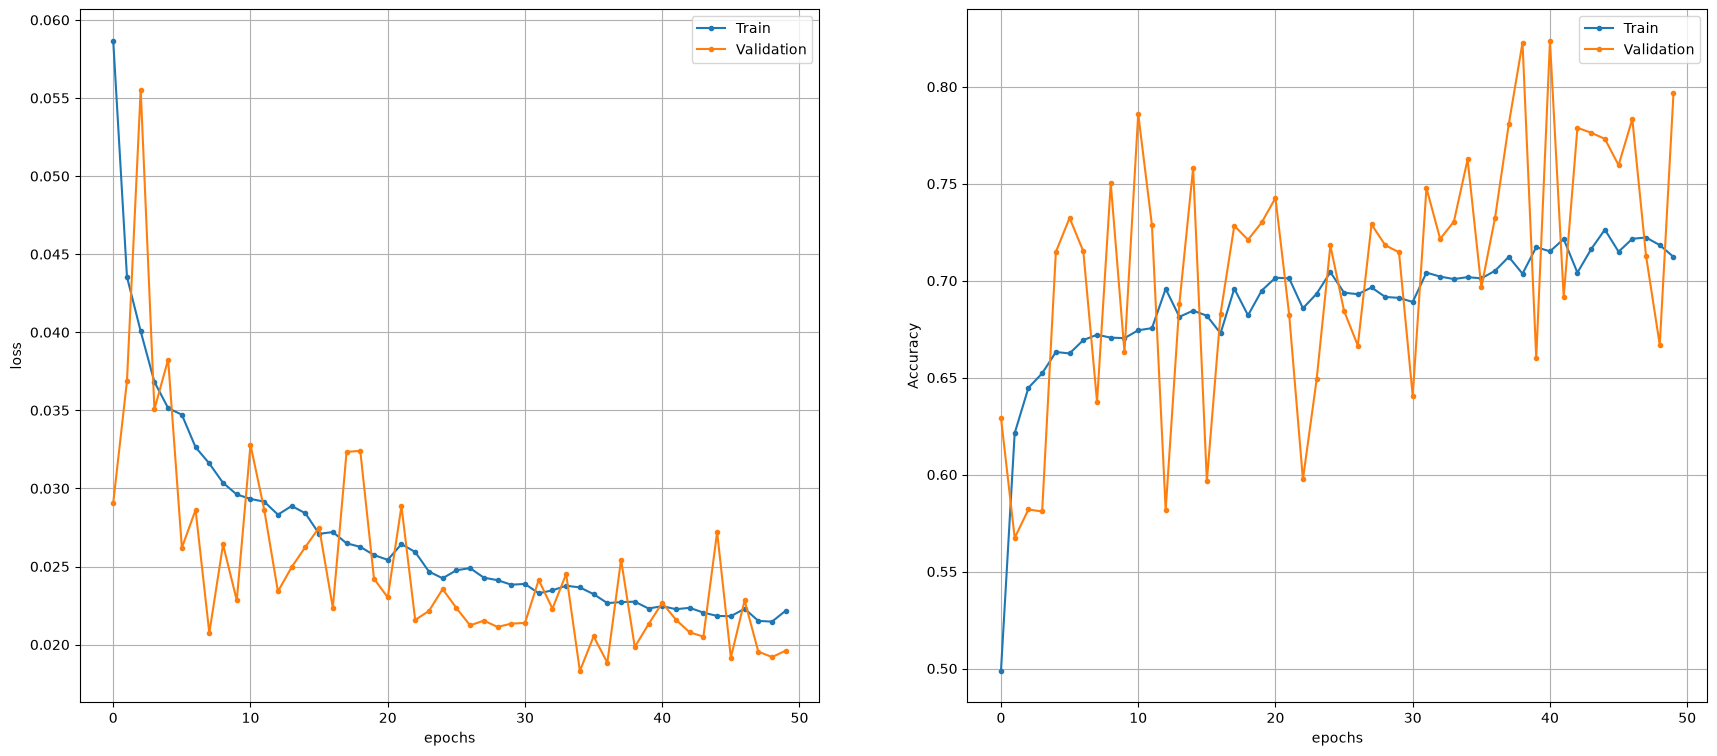

In [4]:
plot_history(history)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


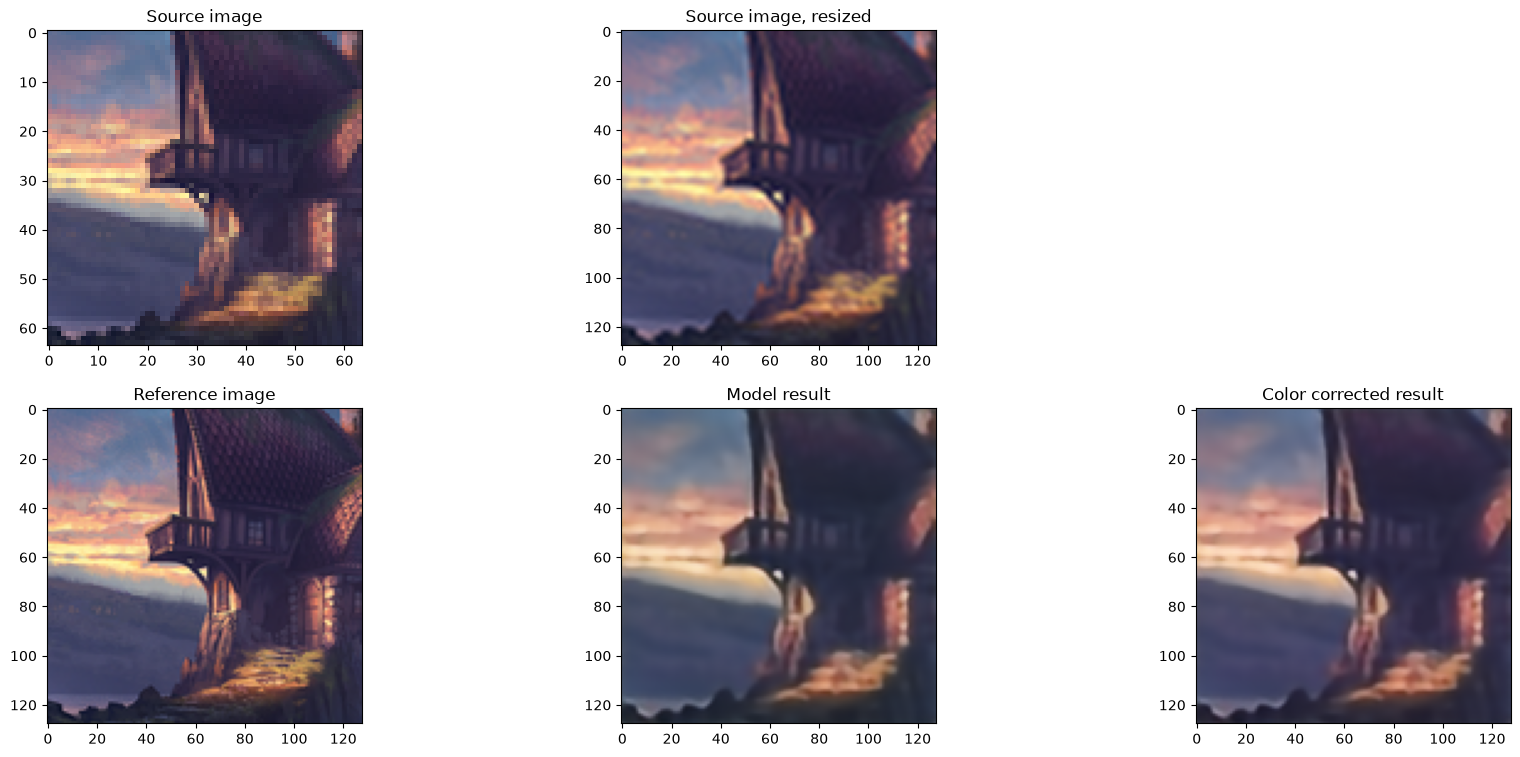

In [5]:
model.load()
from dataset_location import DatasetLocation
x = cv2.imread(os.path.join(DatasetLocation.ROOT, 'test', '1', '3m90fxiwwfo61.png')).astype(np.float32) / 255
y = cv2.imread(os.path.join(DatasetLocation.ROOT, 'test', '2', '3m90fxiwwfo61.png')).astype(np.float32) / 255
visualize_result(model, x, y)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


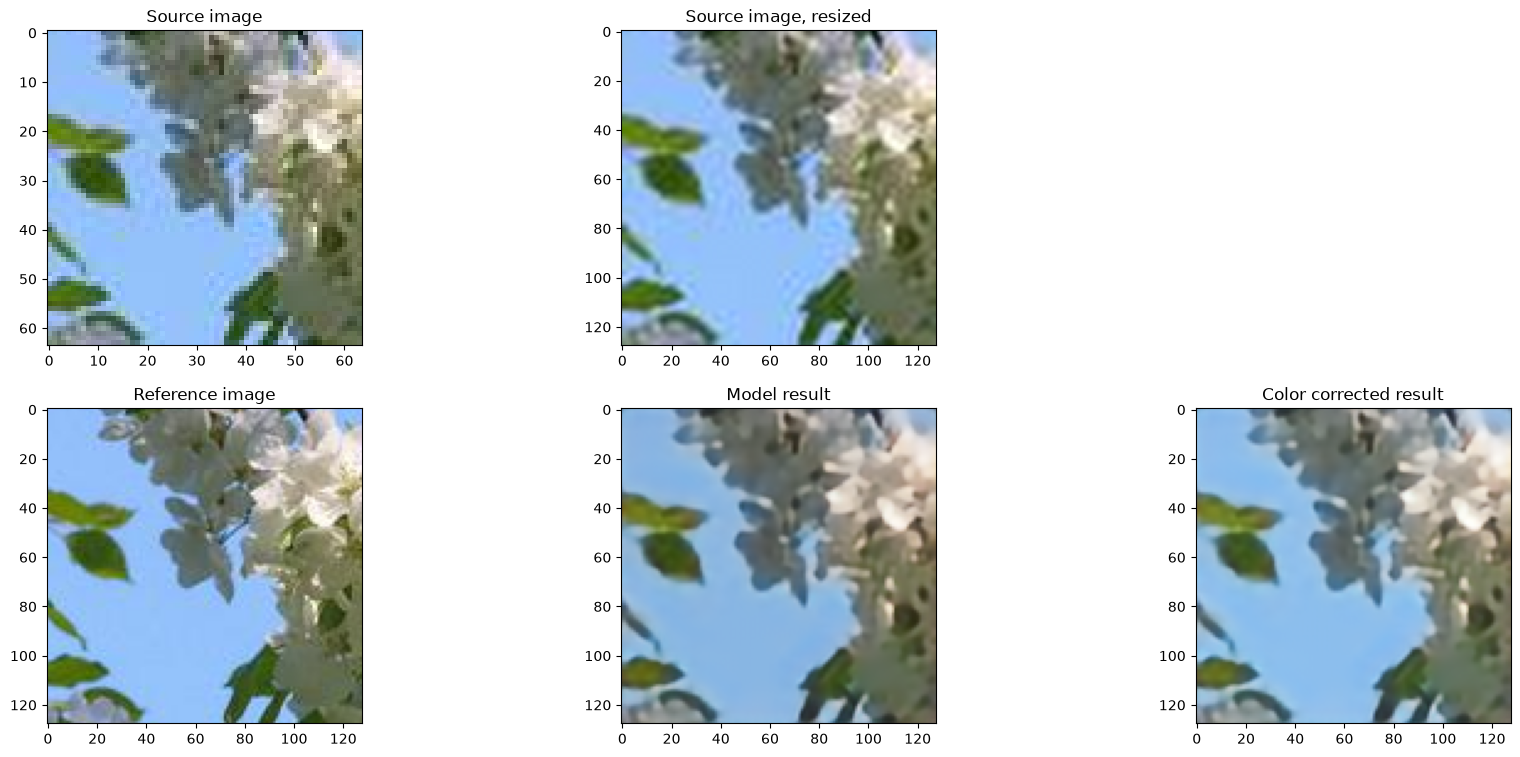

In [6]:
x = cv2.imread(os.path.join(DatasetLocation.ROOT, 'test', '1', '20220419_132620.jpg')).astype(np.float32) / 255
y = cv2.imread(os.path.join(DatasetLocation.ROOT, 'test', '2', '20220419_132620.jpg')).astype(np.float32) / 255
visualize_result(model, x, y)